## Geolocation map of GHCN-d stations

In [ ]:
# setup: load modules and inline plotting

import numpy as np
import netCDF4 as nc
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pyproj import Geod
import pandas as pd
from pathlib import Path
import xarray as xr

print("Cartopy version:", cartopy.__version__)

Cartopy version: 0.24.1


In [ ]:
# set filepaths
ERA_DIR = Path("Data/ERA5")
DATA_DIR = Path('Data/')        

In [2]:
# Haversine / Great circle distance in kilometers
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.deg2rad, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2.0)**2
    return 2*R*np.arcsin(np.sqrt(a))

In [ ]:
def load_landmask(fname):
    """
    Return (lat, lon, land_sea_mask) or None if not available
    """
    if fname is None or not fname.exists():
        return None
    with nc.Dataset(fname, "r") as ds:
        lat = ds.variables["latitude"][:]
        lon = ds.variables["longitude"][:]
        lsm = ds.variables["lsm"][0, :, :] # land binary mask;s 0: ocean; 1: land
    return (np.array(lat), np.array(lon), np.array(lsm))

In [ ]:
# get land mask using ERA5 reanalysis
LSMASK = load_landmask(fname=ERA_DIR/"ERA5reanalysis_landseamask.nc")
late, lone0, lsme0 = LSMASK
# now convert 0-360 to -180-180
idlon1 = np.where((lone0>=0)&(lone0<180))[0]
idlon2 = np.where((lone0>=180)&(lone0<360))[0]
lone = np.concatenate((lone0[idlon2]-360.0, lone0[idlon1]), axis=0)   
lsme = np.concatenate((lsme0[:, idlon2], lsme0[:, idlon1]), axis=1)

In [ ]:
# read information of GHCN-d station, location, operation year info from the inventory list
fname_inventory = 'ghcnd-inventory.txt'
stations = {}  # id -> dict

with open(DATA_DIR + fname_inventory, "r", encoding="utf-8") as f:
    for line in f:
        if len(line) < 45 or line[0].isspace():
            continue  # skip blanks/short lines

        sid = line[0:11].strip()
        fips = sid[:2]   # first two characters denote the FIPS country code
        lat = float(line[12:20].strip())
        lon = float(line[21:30].strip())
        elem = line[31:35].strip()
        first = int(line[36:40].strip())
        last = int(line[41:45].strip())

        rec = stations.get(sid)
        if rec is None:
            stations[sid] = {
                "fips": fips,
                "lat": lat,
                "lon": lon,
                "first": first,
                "last": last,
                "elems": {elem},
            }
        else:
            # update the first and last year if needed
            # add elements
            rec["first"] = min(rec["first"], first)
            rec["last"] = max(rec["last"], last)
            rec["elems"].add(elem)

# --- keep only stations with both TMAX and TMIN --- #
need_tmnmx = {"TMAX", "TMIN"}
filtered = {sid: rec for sid, rec in stations.items()
            if ((need_tmnmx.issubset(rec["elems"])) and (rec["last"]>=1980))}

# pack into a structured array
dtype = np.dtype([
    ("FIPS", "U2"),
    ("ID",   "U11"),
    ("LAT",  "f8"),
    ("LON",  "f8"),
    ("FIRSTYEAR", "i4"),
    ("LASTYEAR", "i4"),
])

data_meta = np.empty(len(filtered), dtype=dtype)
yrs_valid = np.full((len(filtered),), np.nan)
for i, (sid, rec) in enumerate(sorted(filtered.items())):
    data_meta["FIPS"][i] = rec["fips"]
    data_meta["ID"][i] = sid
    data_meta["LAT"][i] = rec["lat"]
    data_meta["LON"][i] = rec["lon"]
    data_meta["FIRSTYEAR"][i] = rec["first"]
    data_meta["LASTYEAR"][i] = rec["last"]
    yrs_valid[i] = min(data_meta["LASTYEAR"][i], 2025) - max(data_meta["FIRSTYEAR"][i], 1980) + 1

In [12]:
# count stations per reanalysis grid (with radius <= 600 km)
TILE_STEP_DEG = 5.0  # space between tile centers
lat_r = np.arange(late.max(), late.min() - TILE_STEP_DEG, -TILE_STEP_DEG)
lon_r = np.arange(lone.min(), lone.max() + TILE_STEP_DEG, TILE_STEP_DEG)

LAT_R, LON_R = np.meshgrid(lat_r, lon_r, indexing='ij')
count_sts = np.zeros_like(LAT_R, dtype=int)
yrs_sts = np.zeros_like(LAT_R)

radius = 600 # km
for i in range(len(lat_r)):
    for j in range(len(lon_r)):
        d = haversine_km(LAT_R[i,j], LON_R[i,j], data_meta["LAT"], data_meta["LON"])
        idvalid = np.where( d<=radius)[0]
        count_sts[i,j] = len(idvalid)
        yrs_sts[i, j] = np.sum(yrs_valid[idvalid])

In [14]:
geod = Geod(ellps="WGS84")

def geodesic_circle(lon0, lat0, radius_km, n=360):
    """Return lat/lon polygon of a geodesic radius on the sphere"""
    # angles from 0-359 deg
    az = np.linspace(0, 360, n, endpoint=False)
    lon0_arr = np.full(n, lon0)
    lat0_arr = np.full(n, lat0)
    dist_arr = np.full(n, radius_km*1000)
    # pyproj.geod.fwd returns lon, lat, given start, azimuth, distance(m)
    lon, lat, _ = geod.fwd(lon0_arr, lat0_arr, az, dist_arr)

    return lon, lat

#### Plot figure for the manuscript

In [ ]:
file_input = Path("Data/GHCNd_report_time_1980-2025.csv")

df = pd.read_csv(
    file_input,
    dtype={
        "ID": "string",
        "SFLAG_TMAX": "string",
    },
)
print(df.columns.tolist())

# Normalize the source flag.
df["SFLAG_TMAX"] = (
    df["SFLAG_TMAX"]
    .astype("string")
    .str.strip()
)

# Convert OBSTIME_TMAX to numeric.
#
# This converts actual missing values, "nan", blank strings,
# and other nonnumeric values to NaN.
df["OBSTIME_TMAX_NUM"] = pd.to_numeric(
    df["OBSTIME_TMAX"],
    errors="coerce",
)

# Make sure coordinates are numeric.
df["LAT"] = pd.to_numeric(df["LAT"], errors="coerce")
df["LON"] = pd.to_numeric(df["LON"], errors="coerce")

# Remove records without valid coordinates.
df = df.dropna(subset=["LAT", "LON"]).copy()
# Default group for missing, or otherwise unclassified records
df["REPORT_GROUP"] = "Local 18-24"

# Group 1: UTC reporting
mask_utc = df["SFLAG_TMAX"].eq("S")

df.loc[mask_utc,"REPORT_GROUP",] = "UTC"

# Non-UTC records
mask_local = ~mask_utc

# Group 2: Local stations with missing reporting time
mask_local_missing = (mask_local & df["OBSTIME_TMAX_NUM"].isna())

df.loc[mask_local_missing,"REPORT_GROUP",] = "Local 18-24"

# Group 3a: 0600 <= reporting time < 1200
mask_local_0600_1200 = (
    mask_local
    & df["OBSTIME_TMAX_NUM"].ge(600)
    & df["OBSTIME_TMAX_NUM"].lt(1200)
)

df.loc[mask_local_0600_1200,"REPORT_GROUP",] = "Local 06-12"

# Group 3b: 1200 <= reporting time < 1800
mask_local_1200_1800 = (
    mask_local
    & df["OBSTIME_TMAX_NUM"].ge(1200)
    & df["OBSTIME_TMAX_NUM"].lt(1800)
)

df.loc[mask_local_1200_1800, "REPORT_GROUP",] = "Local 12-18"

# Group 3c: 1800 <= reporting time <= 2400
mask_local_1800_2400 = (
    mask_local
    & df["OBSTIME_TMAX_NUM"].ge(1800)
    & df["OBSTIME_TMAX_NUM"].le(2400)
)

df.loc[mask_local_1800_2400,"REPORT_GROUP",] = "Local 18-24"

#  Inspect records that were not classified
df_unclassified = df[df["REPORT_GROUP"].isna()].copy()
print(f"Unclassified records: {len(df_unclassified):,}")

if not df_unclassified.empty:
    print(
        df_unclassified[
            ["ID", "SFLAG_TMAX", "OBSTIME_TMAX", "OBSTIME_TMAX_NUM"]
        ]
        .drop_duplicates()
        .head(20)
    )

['ID', 'LAT', 'LON', 'SFLAG_TMAX', 'OBSTIME_TMAX']
Unclassified records: 0


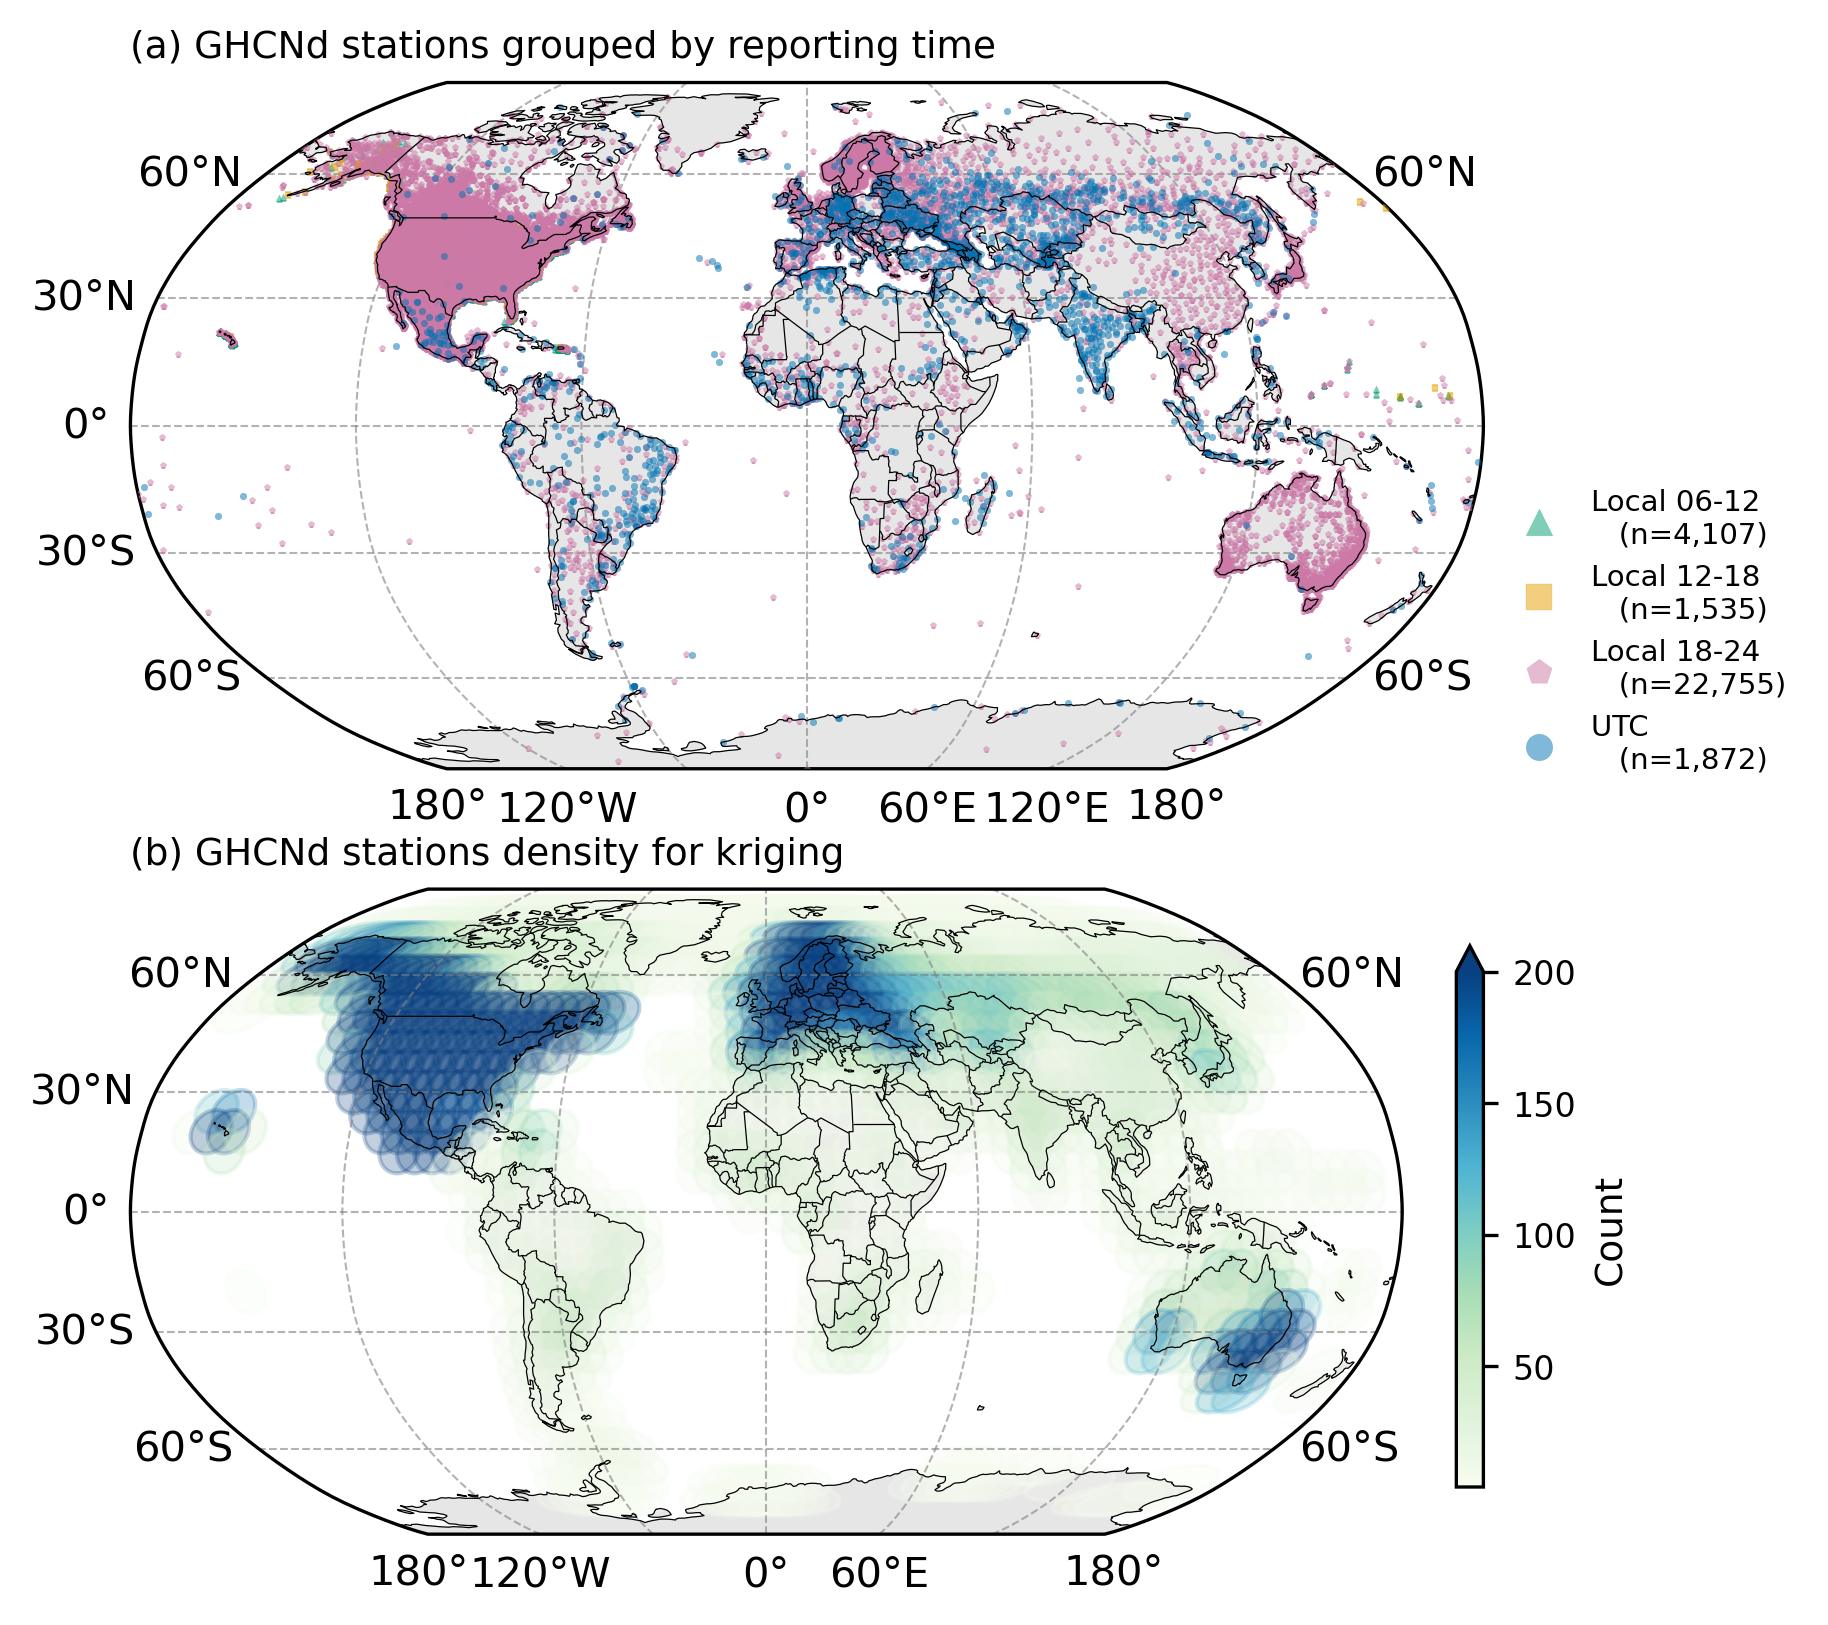

In [ ]:
#  Plot station locations
df_plot = df.copy()

group_order = ["Local 06-12", "Local 12-18", "Local 18-24", "UTC"]

group_markers = {
    "Local 06-12": "^",
    "Local 12-18": "s",
    "Local 18-24": "p",
    "UTC": "o",
}

group_colors = {
    "UTC": "#0072B2",
    "Local 06-12": "#009E73",
    "Local 12-18": "#E69F00",
    "Local 18-24": "#CC79A7",
}

group_zorder = {
    "Local 18-24": 3,
    "Local 06-12": 3,
    "UTC": 3,
    "Local 12-18": 3, 
}

fig, ax = plt.subplots(ncols=1, nrows=2, figsize=(6.5, 5.5), subplot_kw={"projection": ccrs.Robinson()}, dpi=300,)
plt.tight_layout(rect = [0.12, 0.02, 0.86, 1])

ax[0].set_global()
ax[0].add_feature(cfeature.LAND, facecolor="0.9", zorder=0,)
ax[0].add_feature(cfeature.OCEAN, facecolor="white", zorder=0,)

for group in group_order:
    df_group = df_plot[df_plot["REPORT_GROUP"] == group]

    if df_group.empty:
        continue

    ax[0].scatter(
        df_group["LON"],
        df_group["LAT"],
        s=2.5,
        marker=group_markers[group],
        facecolors=  group_colors[group],
        edgecolors = group_colors[group],
        transform=ccrs.PlateCarree(),
        label=f"{group} \n   (n={len(df_group):,})",
        alpha=0.5,
        linewidths=0.1,
        zorder=group_zorder[group],
    )

ax[0].add_feature(cfeature.COASTLINE, linewidth=0.3, zorder=6,)
ax[0].add_feature(cfeature.BORDERS, linewidth=0.3, zorder=6,)

# Gridlines
gl = ax[0].gridlines(draw_labels=True, linewidth=0.5, color="gray", alpha=0.6, linestyle='--')
gl.top_labels = False
gl.right_labels = False

ax[0].set_title("(a) GHCNd stations grouped by reporting time", loc="left", fontsize=9, fontweight="normal")
ax[0].legend(loc="center left", bbox_to_anchor=(1.0, 0.2), fontsize=7, frameon=False, markerscale=4,)

# ------------------------
ax[1].set_global()
# Features
ax[1].add_feature(cfeature.LAND, facecolor="0.9")
ax[1].add_feature(cfeature.OCEAN, facecolor="white")

# scaling color by number of GHCN stations inside circle
vmin = 4
vmax = 200
cmap = plt.cm.GnBu
norm = mcolors.Normalize(vmin=vmin, vmax=vmax, clip=True)

radius = 600 # km
npoly = 360 # polygon points per circle

for i in range(len(lat_r)):
    for j in range(len(lon_r)):
        if count_sts[i, j] < vmin:
            continue
        
        lon_poly, lat_poly = geodesic_circle(lon_r[j], lat_r[i], radius, n=npoly)        
        # temporarily skip borders to avoid errors
        if np.any(np.abs(np.diff(lon_poly)) > 180):
            continue

        ax[1].fill(lon_poly, lat_poly,
                color=cmap(norm(count_sts[i,j])),
                alpha=0.25,
                transform=ccrs.PlateCarree(),
                zorder=2)

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

# add border lines
ax[1].add_feature(cfeature.BORDERS, linewidth=0.3, zorder=3)
ax[1].coastlines(linewidth=0.3, zorder=3)

# Gridlines
gl = ax[1].gridlines(draw_labels=True, linewidth=0.5, color="gray", alpha=0.6, linestyle='--')
gl.top_labels = False
gl.right_labels = False

# Colorbar
cb = plt.colorbar(sm, ax=ax[1], fraction=0.02, pad=0.04, extend='max')
cb.set_label("Count", fontsize=9)
cb.ax.tick_params(labelsize=8)

ax[1].set_title("(b) GHCNd stations density for kriging", loc="left", fontsize=9, fontweight="normal")

plt.show()